In [49]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import math

In [50]:
# ============================================================
# FUNGSI MENAMPILKAN GAMBAR
# ============================================================

def show_image(title, image, cmap=None):
    plt.figure(figsize=(7, 5))

    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap if cmap else "gray")
    else:
        plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))

    plt.title(title)
    plt.axis("off")
    plt.show()

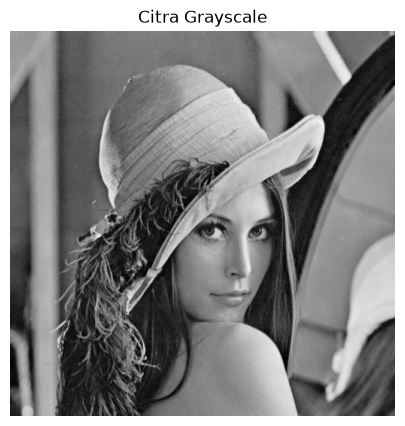

In [51]:
# ============================================================
# LOAD IMAGE
# ============================================================

image_path = "lenna.png"

img = cv.imread(image_path)

if img is None:
    raise FileNotFoundError(
        f"Gambar tidak ditemukan: {image_path}"
    )

# Ubah menjadi grayscale
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

show_image("Citra Grayscale", img_gray, "gray")

In [52]:
# ============================================================
# FUNGSI KONVOLUSI TANPA LIBRARY KONVOLUSI
# ============================================================

def convolution2d(image, kernel, padding=1, stride=1):

    image = image.astype(np.float32)
    kernel = np.array(kernel, dtype=np.float32)

    kernel_height, kernel_width = kernel.shape
    image_height, image_width = image.shape

    # Padding
    padded_image = np.pad(
        image,
        (
            (padding, padding),
            (padding, padding)
        ),
        mode="constant",
        constant_values=0
    )

    output_height = (
        (image_height + 2 * padding - kernel_height)
        // stride
    ) + 1

    output_width = (
        (image_width + 2 * padding - kernel_width)
        // stride
    ) + 1

    output = np.zeros(
        (output_height, output_width),
        dtype=np.float32
    )

    # Proses konvolusi
    for y in range(0, output_height):

        for x in range(0, output_width):

            y_start = y * stride
            x_start = x * stride

            region = padded_image[
                y_start:y_start + kernel_height,
                x_start:x_start + kernel_width
            ]

            output[y, x] = np.sum(region * kernel)

    # Batasi nilai 0-255
    output = np.clip(output, 0, 255)

    return output.astype(np.uint8)

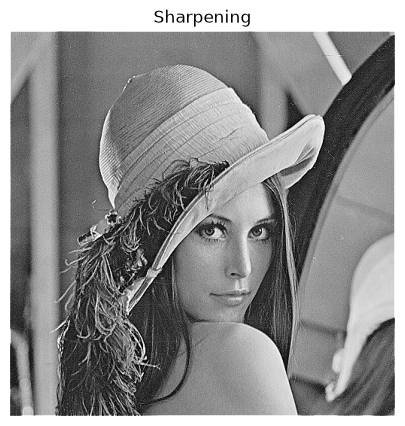

In [53]:
# ============================================================
# SHARPENING
# ============================================================

kernel_sharpen = np.array([
    [0, -1,  0],
    [-1, 5, -1],
    [0, -1,  0]
])

sharpen = convolution2d(
    img_gray,
    kernel_sharpen,
    padding=1
)

show_image(
    "Sharpening",
    sharpen,
    "gray"
)

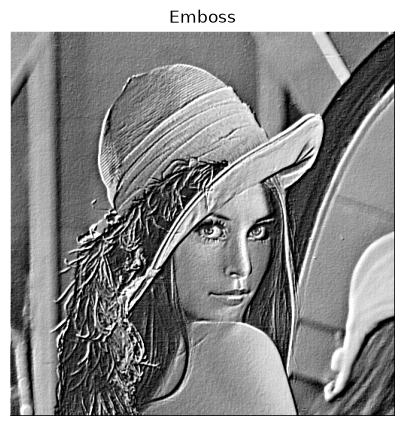

In [54]:
# ============================================================
# EMBOSS
# ============================================================

kernel_emboss = np.array([
    [-2, -1, 0],
    [-1,  1, 1],
    [ 0,  1, 2]
])

emboss = convolution2d(
    img_gray,
    kernel_emboss,
    padding=1
)

show_image(
    "Emboss",
    emboss,
    "gray"
)

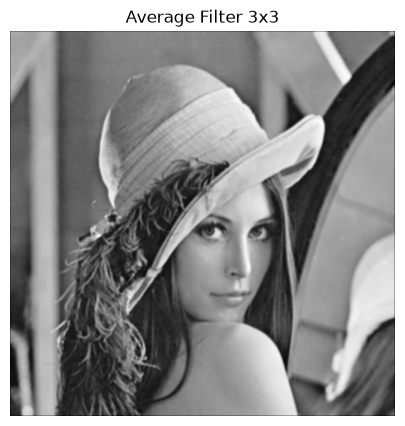

In [55]:
# ============================================================
# AVERAGE FILTER
# ============================================================

kernel_average = np.ones((3, 3), dtype=np.float32) / 9

average = convolution2d(
    img_gray,
    kernel_average,
    padding=1
)

show_image(
    "Average Filter 3x3",
    average,
    "gray"
)

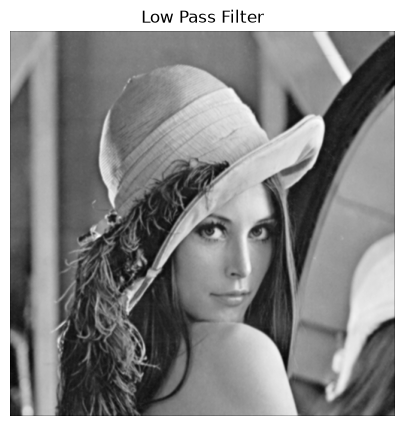

In [56]:
# ============================================================
# LOW PASS FILTER
# ============================================================

kernel_lowpass = np.array([
    [1, 1, 1],
    [1, 4, 1],
    [1, 1, 1]
], dtype=np.float32) / 12

lowpass = convolution2d(
    img_gray,
    kernel_lowpass,
    padding=1
)

show_image(
    "Low Pass Filter",
    lowpass,
    "gray"
)

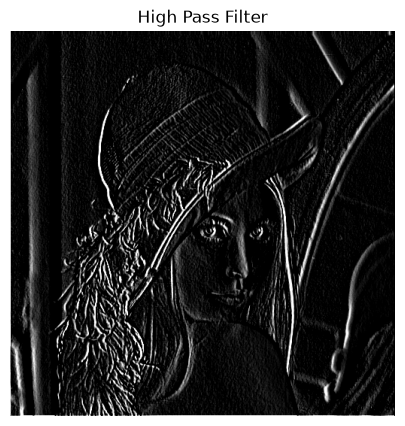

In [57]:
# ============================================================
# HIGH PASS FILTER
# ============================================================

kernel_highpass = np.array([
    [-1, 0, 1],
    [-1, 0, 3],
    [-3, 0, 1]
])

highpass = convolution2d(
    img_gray,
    kernel_highpass,
    padding=1
)

show_image(
    "High Pass Filter",
    highpass,
    "gray"
)

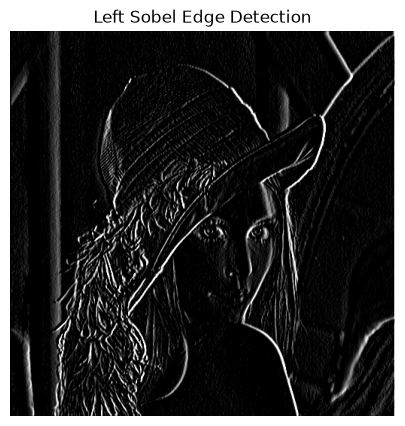

In [58]:
# ============================================================
# LEFT SOBEL EDGE DETECTION
# ============================================================

kernel_left_sobel = np.array([
    [1,  0, -1],
    [2,  0, -2],
    [1,  0, -1]
])

left_sobel = convolution2d(
    img_gray,
    kernel_left_sobel,
    padding=1
)

show_image(
    "Left Sobel Edge Detection",
    left_sobel,
    "gray"
)

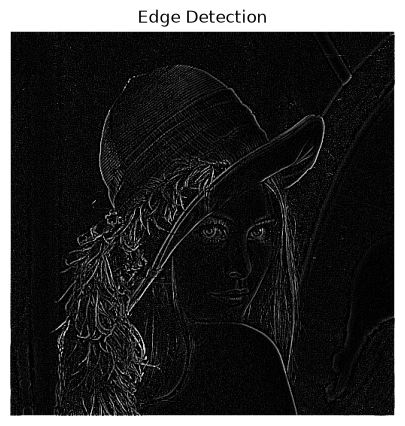

In [59]:
# ============================================================
# EDGE DETECTION
# ============================================================

kernel_edge = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

edge = convolution2d(
    img_gray,
    kernel_edge,
    padding=1
)

show_image(
    "Edge Detection",
    edge,
    "gray"
)

In [60]:
kernel_size = 21

sigma = math.sqrt(kernel_size)

gaussian_kernel = cv.getGaussianKernel(
    kernel_size,
    sigma
)

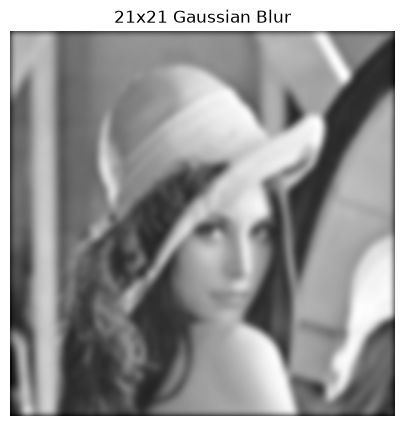

In [61]:
gauss_kernel = (
    gaussian_kernel @ gaussian_kernel.transpose()
)

gaussian_21 = convolution2d(
    img_gray,
    gauss_kernel,
    padding=kernel_size // 2
)

show_image(
    "21x21 Gaussian Blur",
    gaussian_21,
    "gray"
)

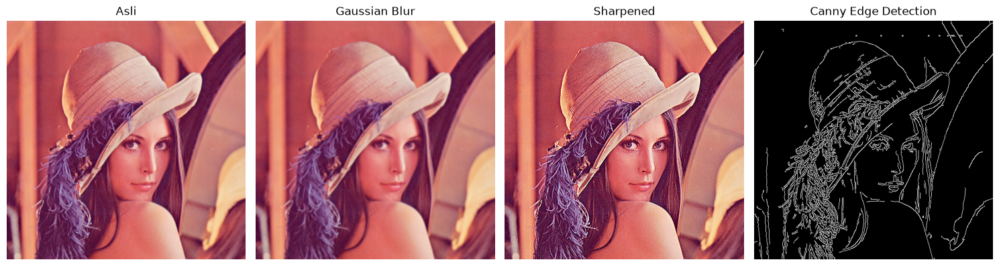

In [62]:
# ============================================================
# PERCOBAAN 1
# Gaussian Blur, Sharpen, Canny
# ============================================================

# Gaussian Blur
blur = cv.GaussianBlur(
    img,
    (7, 7),
    1
)

# Sharpen menggunakan filter2D
kernel_sharpen_rgb = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpen_rgb = cv.filter2D(
    img,
    -1,
    kernel_sharpen_rgb
)

# Canny
edges = cv.Canny(
    img,
    100,
    200
)

# Tampilkan
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title("Asli")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(cv.cvtColor(blur, cv.COLOR_BGR2RGB))
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(cv.cvtColor(sharpen_rgb, cv.COLOR_BGR2RGB))
plt.title("Sharpened")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

In [63]:
# ============================================================
# SHOW SIDE BY SIDE
# ============================================================

def show_side_by_side(images, titles):

    plt.figure(figsize=(15, 5))

    for i, (image, title) in enumerate(
        zip(images, titles)
    ):

        plt.subplot(1, len(images), i + 1)

        if len(image.shape) == 2:
            plt.imshow(image, cmap="gray")
        else:
            plt.imshow(
                cv.cvtColor(
                    image,
                    cv.COLOR_BGR2RGB
                )
            )

        plt.title(title)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

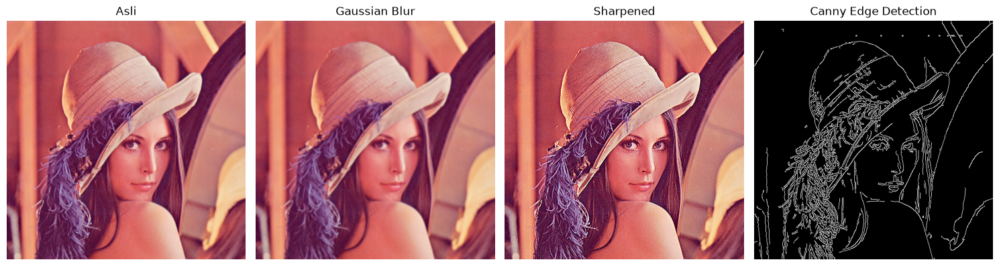

In [64]:
show_side_by_side(
    [
        img,
        blur,
        sharpen_rgb,
        edges
    ],
    [
        "Asli",
        "Gaussian Blur",
        "Sharpened",
        "Canny Edge Detection"
    ]
)

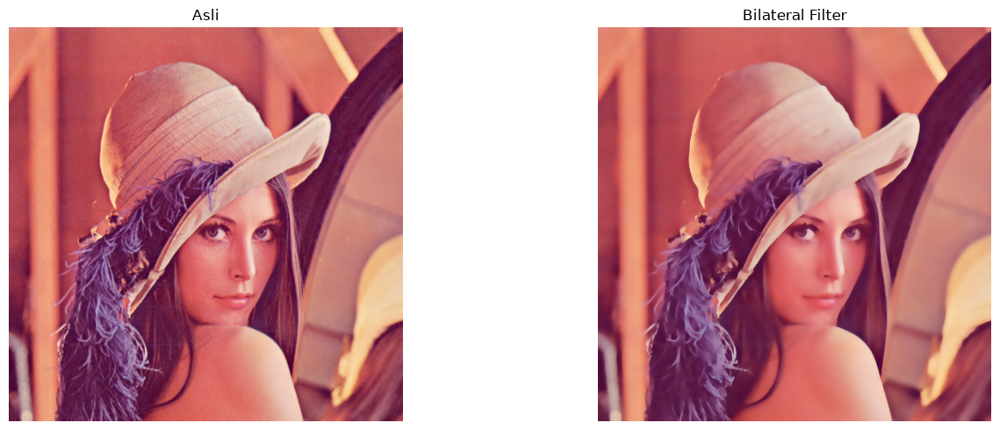

In [65]:
# ============================================================
# PERCOBAAN 2
# BILATERAL FILTER
# ============================================================

bilateral = cv.bilateralFilter(
    img,
    9,
    75,
    75
)

show_side_by_side(
    [
        img,
        bilateral
    ],
    [
        "Asli",
        "Bilateral Filter"
    ]
)

In [66]:
# ============================================================
# GUIDED FILTER
# ============================================================

if hasattr(cv, "ximgproc"):

    guided = cv.ximgproc.guidedFilter(
        guide=img,
        src=img,
        radius=10,
        eps=100
    )

    show_side_by_side(
        [
            img,
            bilateral,
            guided
        ],
        [
            "Asli",
            "Bilateral Filter",
            "Guided Filter"
        ]
    )

else:

    print(
        "Guided Filter tidak tersedia."
    )

    print(
        "Install opencv-contrib-python."
    )

Guided Filter tidak tersedia.
Install opencv-contrib-python.


In [67]:
pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.


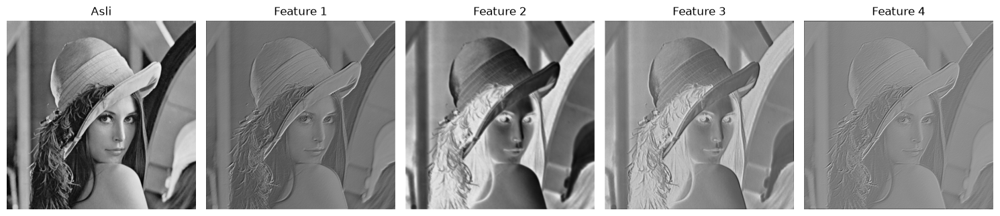

In [68]:
# ============================================================
# PERCOBAAN 3
# FILTERING PADA CNN
# ============================================================

import torch
import torch.nn as nn


class SimpleCNN(nn.Module):

    def __init__(self):

        super(SimpleCNN, self).__init__()

        self.conv1 = nn.Conv2d(
            1,
            4,
            kernel_size=4,
            stride=1,
            padding=1
        )

    def forward(self, x):

        return self.conv1(x)


# Ubah grayscale menjadi tensor
img_tensor = (
    torch.from_numpy(
        img_gray.astype(np.float32)
    )
    .unsqueeze(0)
    .unsqueeze(0)
    / 255.0
)


# Buat model
model = SimpleCNN()


# Forward
with torch.no_grad():

    features = model(
        img_tensor
    )


# Tampilkan feature maps
plt.figure(figsize=(15, 4))

plt.subplot(
    1,
    5,
    1
)

plt.imshow(
    img_gray,
    cmap="gray"
)

plt.title("Asli")
plt.axis("off")


for i in range(4):

    plt.subplot(
        1,
        5,
        i + 2
    )

    plt.imshow(
        features[0, i].numpy(),
        cmap="gray"
    )

    plt.title(
        f"Feature {i + 1}"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()

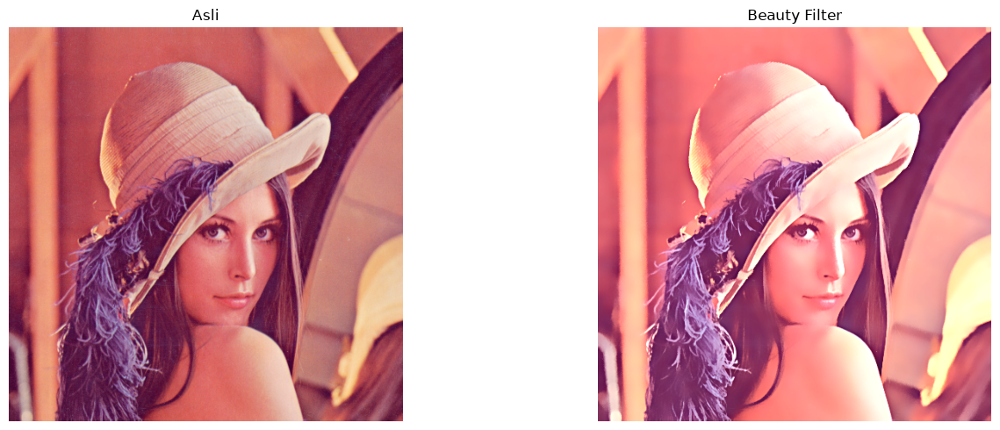

In [69]:
# ============================================================
# PERCOBAAN 4
# BEAUTY FILTER
# ============================================================

# Step 1: smoothing
smooth = cv.bilateralFilter(
    img,
    15,
    50,
    50
)

# Step 2: unsharp masking
gaussian = cv.GaussianBlur(
    smooth,
    (0, 0),
    3
)

sharpened = cv.addWeighted(
    smooth,
    1.5,
    gaussian,
    -0.5,
    0
)

# Step 3: brightness dan contrast
alpha = 1.2
beta = 15

beauty = cv.convertScaleAbs(
    sharpened,
    alpha=alpha,
    beta=beta
)


show_side_by_side(
    [
        img,
        beauty
    ],
    [
        "Asli",
        "Beauty Filter"
    ]
)

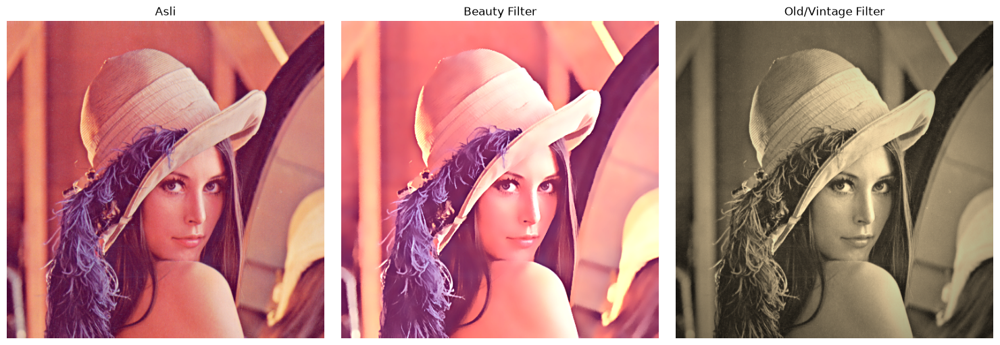

In [70]:
# ============================================================
# VINTAGE FILTER
# ============================================================

sepia_kernel = np.array([
    [0.272, 0.534, 0.131],
    [0.349, 0.686, 0.168],
    [0.393, 0.769, 0.189]
])

sepia = cv.transform(
    img,
    sepia_kernel
)

sepia = np.clip(
    sepia,
    0,
    255
).astype(np.uint8)


# Vignette
rows, cols = img.shape[:2]

kernel_x = cv.getGaussianKernel(
    cols,
    cols * 0.6
)

kernel_y = cv.getGaussianKernel(
    rows,
    rows * 0.6
)

kernel = kernel_y @ kernel_x.T

mask = kernel / kernel.max()

vignette = sepia.copy()

for i in range(3):

    vignette[:, :, i] = (
        vignette[:, :, i] * mask
    )


show_side_by_side(
    [
        img,
        beauty,
        vignette
    ],
    [
        "Asli",
        "Beauty Filter",
        "Old/Vintage Filter"
    ]
)

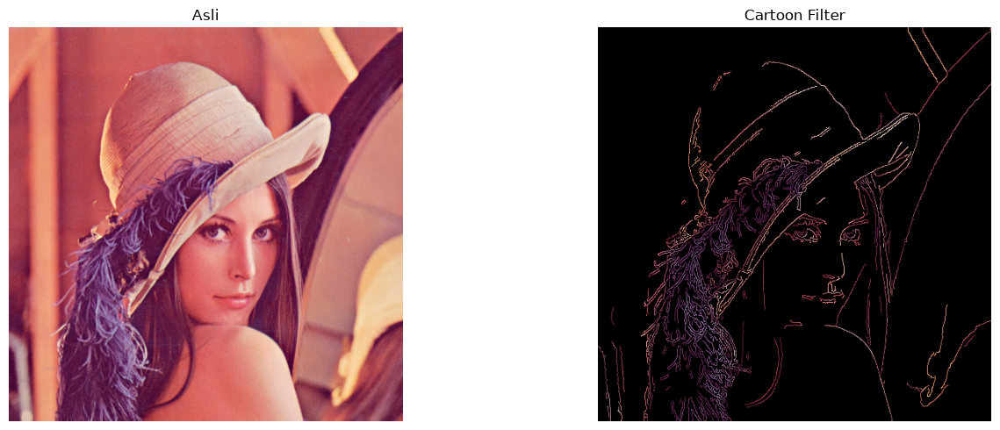

In [71]:
# ============================================================
# PERCOBAAN 5 / TUGAS KREASI
# CARTOON FILTER
# ============================================================

def kartun(image):

    # 1. Penghalusan warna
    smooth = cv.bilateralFilter(
        image,
        9,
        75,
        75
    )

    # 2. Grayscale
    gray = cv.cvtColor(
        image,
        cv.COLOR_BGR2GRAY
    )

    # 3. Canny Edge
    edges = cv.Canny(
        gray,
        100,
        200
    )

    # 4. Threshold
    edges = cv.threshold(
        edges,
        100,
        255,
        cv.THRESH_BINARY
    )[1]

    # 5. Ubah edge menjadi 3 channel
    edges = cv.cvtColor(
        edges,
        cv.COLOR_GRAY2BGR
    )

    # 6. Kombinasikan warna dengan edge
    cartoon = cv.bitwise_and(
        smooth,
        edges
    )

    return cartoon


cartoon = kartun(img)


show_side_by_side(
    [
        img,
        cartoon
    ],
    [
        "Asli",
        "Cartoon Filter"
    ]
)

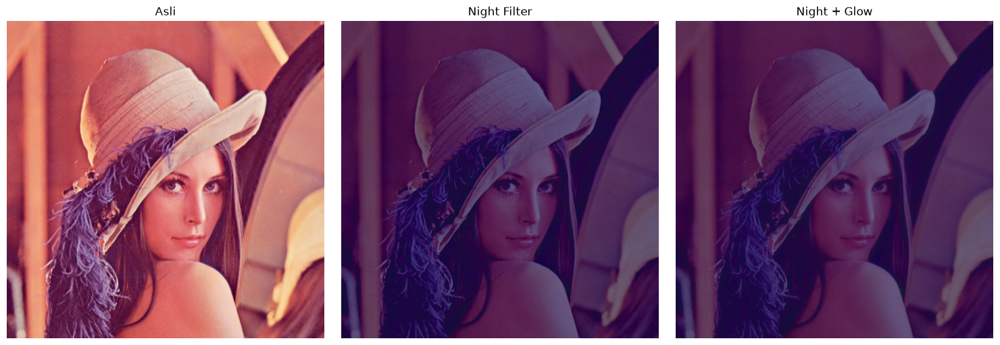

In [72]:
# ============================================================
# PERCOBAAN 6
# NIGHT FILTER
# ============================================================

# Kurangi brightness
night = cv.convertScaleAbs(
    img,
    alpha=0.5,
    beta=-20
)

# Beri nuansa biru
blue_tint = np.zeros_like(
    night
)

blue_tint[:, :, 0] = 50

night = cv.add(
    night,
    blue_tint
)

# Glow
blur_night = cv.GaussianBlur(
    night,
    (0, 0),
    5
)

night_glow = cv.addWeighted(
    night,
    0.8,
    blur_night,
    0.2,
    0
)


show_side_by_side(
    [
        img,
        night,
        night_glow
    ],
    [
        "Asli",
        "Night Filter",
        "Night + Glow"
    ]
)

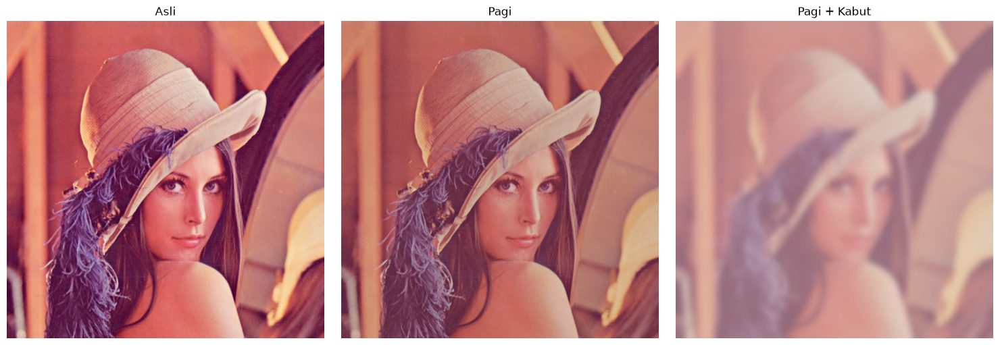

In [73]:
# ============================================================
# PERCOBAAN 7
# MORNING + FOG
# ============================================================

# Step 1: Kurangi kontras dan cerahkan
alpha = 0.9
beta = 20

morning = cv.convertScaleAbs(
    img,
    alpha=alpha,
    beta=beta
)

# Step 2: Tambahkan warna hangat
warm_tint = np.full_like(
    morning,
    (40, 70, 120)
)

morning = cv.addWeighted(
    morning,
    0.8,
    warm_tint,
    0.2,
    0
)


# Step 3: Fog menggunakan Gaussian
kernel_size = 31

kernel = cv.getGaussianKernel(
    kernel_size,
    -1
)

kernel = kernel @ kernel.T

fog = cv.filter2D(
    morning,
    -1,
    kernel
)

# Tambahkan lapisan putih
white_layer = np.full_like(
    fog,
    255
)

fog = cv.addWeighted(
    fog,
    0.7,
    white_layer,
    0.3,
    0
)


show_side_by_side(
    [
        img,
        morning,
        fog
    ],
    [
        "Asli",
        "Pagi",
        "Pagi + Kabut"
    ]
)

TUGAS 1 - Mean Filter vs Median Filter

1. menambahkan Salt and Pepper Noise,
2. Mean Filter 3×3,
3. Median Filter 3×3,
4. membandingkan hasilnya

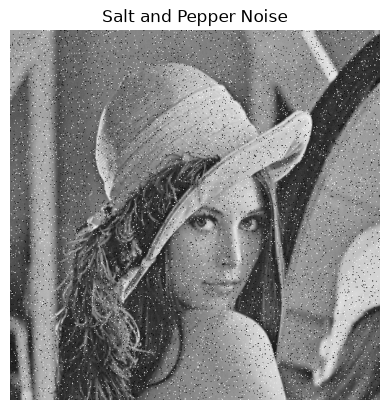

In [76]:
# ==========================================
# 1a. SALT AND PEPPER NOISE
# ==========================================

def salt_pepper_noise(image, amount=0.05):

    noisy = image.copy()

    # Jumlah piksel yang diberi noise
    num_pixels = int(image.size * amount)

    # Noise putih (Salt)
    y = np.random.randint(
        0,
        image.shape[0],
        num_pixels // 2
    )

    x = np.random.randint(
        0,
        image.shape[1],
        num_pixels // 2
    )

    noisy[y, x] = 255

    # Noise hitam (Pepper)
    y = np.random.randint(
        0,
        image.shape[0],
        num_pixels // 2
    )

    x = np.random.randint(
        0,
        image.shape[1],
        num_pixels // 2
    )

    noisy[y, x] = 0

    return noisy


# Citra grayscale
img_gray = cv.cvtColor(
    img,
    cv.COLOR_BGR2GRAY
)

# Tambahkan Salt and Pepper Noise
noisy = salt_pepper_noise(
    img_gray,
    amount=0.05
)

# Tampilkan
plt.imshow(noisy, cmap="gray")
plt.title("Salt and Pepper Noise")
plt.axis("off")
plt.show()

In [77]:
# ==========================================
# 1b. MEAN FILTER 3x3
# ==========================================

mean_filter = cv.blur(
    noisy,
    (3, 3)
)


# ==========================================
# 1b. MEDIAN FILTER 3x3
# ==========================================

median_filter = cv.medianBlur(
    noisy,
    3
)

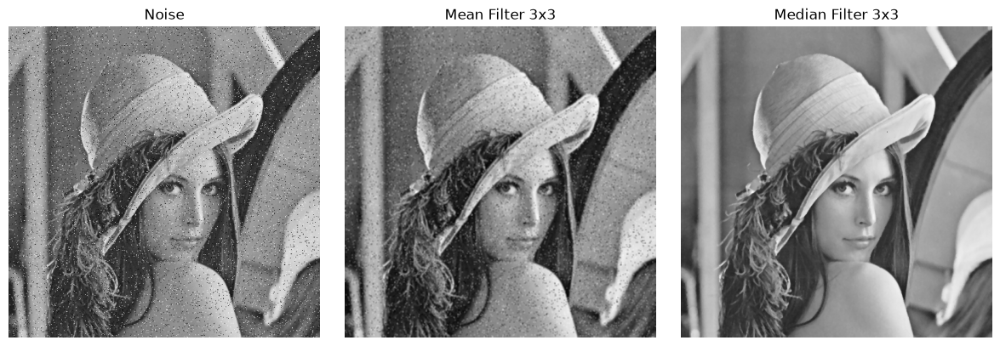

In [78]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(noisy, cmap="gray")
plt.title("Noise")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mean_filter, cmap="gray")
plt.title("Mean Filter 3x3")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(median_filter, cmap="gray")
plt.title("Median Filter 3x3")
plt.axis("off")

plt.tight_layout()
plt.show()

Amati dan analisis secara visual mengapa Median Filter jauh lebih bersih dalam menghapus noise tersebut dibanding Mean Filter.

Median Filter lebih bersih dalam menghilangkan Salt and Pepper Noise karena menggunakan nilai tengah dari piksel-piksel dalam kernel 3×3. Nilai noise yang sangat tinggi atau sangat rendah tidak terlalu memengaruhi nilai median. Sementara itu, Mean Filter menggunakan nilai rata-rata sehingga piksel noise bernilai 0 atau 255 ikut memengaruhi hasil perhitungan. Akibatnya, Mean Filter dapat menghasilkan citra yang lebih blur dan masih menyisakan pengaruh noise.

TUGAS 2 — Sharpening 3×3 vs 5×5

In [82]:
# ==========================================
# 2a. SHARPENING KERNEL 3x3
# ==========================================

kernel_3x3 = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
])


# ==========================================
# 2a. SHARPENING KERNEL 5x5
# ==========================================

kernel_5x5 = np.array([
    [ 0,  0, -1,  0,  0],
    [ 0, -1, -2, -1,  0],
    [-1, -2, 17, -2, -1],
    [ 0, -1, -2, -1,  0],
    [ 0,  0, -1,  0,  0]
])

In [ ]:
# ==========================================
# 2b. BUAT CITRA BLURRY
# ==========================================

blurry = cv.GaussianBlur(
    img_gray,
    (7, 7),
    2
)

In [84]:
# Sharpening 3x3
sharpen_3x3 = cv.filter2D(
    blurry,
    -1,
    kernel_3x3
)

In [85]:
# Sharpening 5x5
sharpen_5x5 = cv.filter2D(
    blurry,
    -1,
    kernel_5x5
)

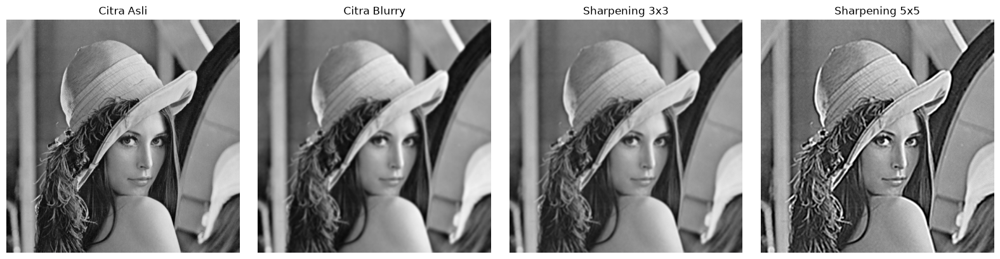

In [86]:
# ==========================================
# 2c. TAMPILKAN HASIL PERBANDINGAN
# ==========================================

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(img_gray, cmap="gray")
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(blurry, cmap="gray")
plt.title("Citra Blurry")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(sharpen_3x3, cmap="gray")
plt.title("Sharpening 3x3")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(sharpen_5x5, cmap="gray")
plt.title("Sharpening 5x5")
plt.axis("off")

plt.tight_layout()
plt.show()

TUGAS 3 — Filter Kartun

In [79]:
# ==========================================
# 3a. FUNGSI KARTUN
# ==========================================

def kartun(image):

    # --------------------------------------
    # 1. Penghalusan warna
    # Bilateral Filter
    # --------------------------------------

    smooth = cv.bilateralFilter(
        image,
        9,
        75,
        75
    )


    # --------------------------------------
    # 2. Ubah ke grayscale
    # --------------------------------------

    gray = cv.cvtColor(
        image,
        cv.COLOR_BGR2GRAY
    )


    # --------------------------------------
    # 3. Deteksi garis tepi
    # menggunakan Canny Edge
    # --------------------------------------

    edges = cv.Canny(
        gray,
        100,
        200
    )


    # --------------------------------------
    # 4. Jadikan edge sebagai mask
    # --------------------------------------

    edges = cv.threshold(
        edges,
        100,
        255,
        cv.THRESH_BINARY
    )[1]


    # --------------------------------------
    # 5. Ubah edge menjadi 3 channel
    # --------------------------------------

    edges = cv.cvtColor(
        edges,
        cv.COLOR_GRAY2BGR
    )


    # --------------------------------------
    # 6. Gabungkan Bilateral + Edge
    # --------------------------------------

    cartoon_image = cv.bitwise_and(
        smooth,
        edges
    )


    return cartoon_image

In [80]:
cartoon_result = kartun(img)

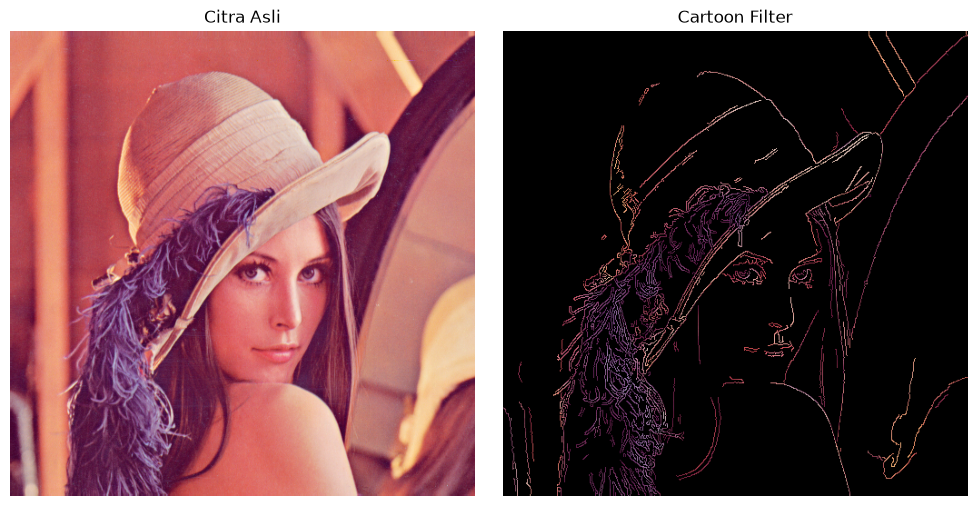

In [81]:
# ==========================================
# 3b. TAMPILKAN ASLI DAN KARTUN
# ==========================================

plt.figure(figsize=(10, 5))

# Citra asli
plt.subplot(1, 2, 1)

plt.imshow(
    cv.cvtColor(
        img,
        cv.COLOR_BGR2RGB
    )
)

plt.title("Citra Asli")
plt.axis("off")


# Citra kartun
plt.subplot(1, 2, 2)

plt.imshow(
    cv.cvtColor(
        cartoon_result,
        cv.COLOR_BGR2RGB
    )
)

plt.title("Cartoon Filter")
plt.axis("off")


plt.tight_layout()
plt.show()